# Email Spam Detection with Machine Learning

## 1. Loading the Dataset

In this project, I am using the SMS Spam Collection dataset to identify spam and genuine messages. The dataset contains text messages labelled as spam or ham. First, I will load the dataset and check the number of messages in each category.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Load the dataset
df = pd.read_csv(
    "SMSSpamCollection.csv",
    sep="\t",
    header=None,
    names=["Category", "Message"],
    encoding="utf-8"
)

df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Checking the Dataset

Now I will check how many messages are present in the dataset and count the spam and ham messages. This will help me understand how the messages are distributed.

In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Count spam and ham messages
category_counts = df["Category"].value_counts()

print("\nMessage counts:")
print(category_counts)

# Calculate percentage of each category
category_percentage = df["Category"].value_counts(normalize=True) * 100

print("\nMessage percentages:")
print(category_percentage.round(2))

Dataset shape: (5572, 2)

Message counts:
Category
ham     4825
spam     747
Name: count, dtype: int64

Message percentages:
Category
ham     86.59
spam    13.41
Name: proportion, dtype: float64


## Message Distribution

The dataset contains more ham messages than spam messages. I will use a bar chart to compare the number of messages in both categories.

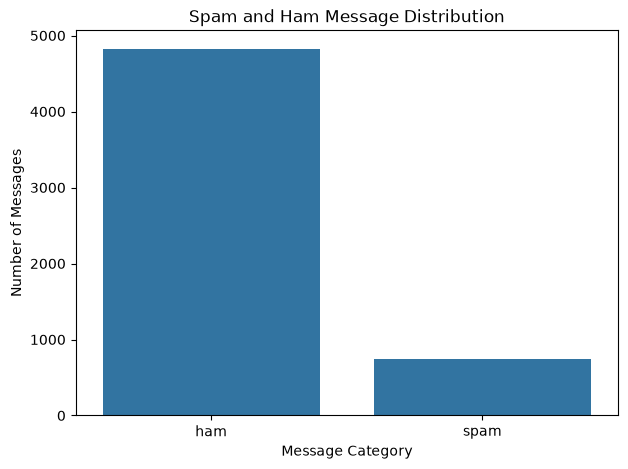

In [3]:
# Plot the number of spam and ham messages
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Category")

plt.title("Spam and Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

## Observation

The graph shows that ham messages are much higher in number than spam messages. Out of 5,572 messages, 4,825 are ham and 747 are spam. This means the dataset is imbalanced, as genuine messages make up most of the data.

## 3. Text Preprocessing

Before training the models, I need to clean the message text. I will convert all messages to lowercase, remove punctuation and numbers, and remove common words that do not add much meaning to the message.

In [4]:
# Function to clean message text
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()

    # Remove common English stopwords
    stop_words = {
        "the", "is", "are", "am", "a", "an", "and", "or",
        "in", "on", "at", "to", "for", "of", "it", "this",
        "that", "you", "your", "me", "my", "we", "they",
        "he", "she", "was", "were", "be", "been", "with"
    }

    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# Apply text cleaning to all messages
df["Clean_Message"] = df["Message"].apply(clean_text)

# Display original and cleaned messages
df[["Message", "Clean_Message"]].head()

,Message,Clean_Message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only bug...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think goes usf lives around here th...


### Observation

After preprocessing, the messages are converted into lowercase text and unnecessary punctuation and numbers are removed. Some common English words are also removed. The original messages are kept in a separate column so that I can compare them with the cleaned messages.

## 4. TF-IDF Feature Extraction

Machine learning models cannot directly understand text messages, so I need to convert the messages into numerical values.

For this, I will use TF-IDF (Term Frequency-Inverse Document Frequency).

TF-IDF measures how important a word is in a message compared to all the messages in the dataset. Words that are useful for identifying a message get higher importance, while very common words get lower importance.

## 5. Splitting the Dataset and Applying TF-IDF

I will divide the messages into training and testing sets. The training data will be used to train the machine learning models, while the testing data will help check their performance.

After splitting the data, I will use TF-IDF to convert the messages into numerical features.

In [5]:
# Separate messages and their categories
X = df["Clean_Message"]
y = df["Category"]

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into TF-IDF numerical features
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display the sizes of training and testing data
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 7502)
Testing data shape: (1115, 7502)


## 6. Training Machine Learning Models

In this section, I will train two machine learning models to classify messages as spam or ham.

First, I will use Multinomial Naive Bayes, which is commonly used for text classification. Then, I will train Logistic Regression and compare the results of both models.

In [6]:
# Create the Multinomial Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Both models have been trained successfully.")

Both models have been trained successfully.


## 7. Making Predictions

After training both models, I will use them to predict whether the test messages are spam or ham. These predictions will be used to compare the performance of the models.

In [7]:
# Predict message categories using both models
nb_predictions = nb_model.predict(X_test_tfidf)
lr_predictions = lr_model.predict(X_test_tfidf)

# Display a few actual and predicted results
prediction_results = pd.DataFrame({
    "Actual Category": y_test.values,
    "Naive Bayes Prediction": nb_predictions,
    "Logistic Regression Prediction": lr_predictions
})

prediction_results.head(10)

,Actual Category,Naive Bayes Prediction,Logistic Regression Prediction
0,ham,ham,ham
1,ham,ham,ham
2,ham,ham,ham
3,spam,spam,spam
4,ham,ham,ham
5,ham,ham,ham
6,ham,ham,ham
7,ham,ham,ham
8,ham,ham,ham
9,ham,ham,ham


## 8. Model Evaluation

In this section, I will compare the performance of both models using accuracy, precision, recall and F1-score. These metrics will help me understand how well each model identifies spam and genuine messages.

In [8]:
# Calculate evaluation metrics for both models
results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions)
    ],
    "Precision": [
        precision_score(y_test, nb_predictions, pos_label="spam"),
        precision_score(y_test, lr_predictions, pos_label="spam")
    ],
    "Recall": [
        recall_score(y_test, nb_predictions, pos_label="spam"),
        recall_score(y_test, lr_predictions, pos_label="spam")
    ],
    "F1-Score": [
        f1_score(y_test, nb_predictions, pos_label="spam"),
        f1_score(y_test, lr_predictions, pos_label="spam")
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.9605,1.0,0.7047,0.8268
1,Logistic Regression,0.9659,1.0,0.7450,0.8538


### Observation

Both models achieved good accuracy. Logistic Regression performed slightly better than Multinomial Naive Bayes in accuracy, recall and F1-score. Both models achieved 100% precision on the test data. Logistic Regression identified a higher percentage of actual spam messages, so it performed better overall in this comparison.

## 9. Confusion Matrix

A confusion matrix helps to understand the correct and incorrect predictions made by a classification model. I will create confusion matrices for both models to compare their spam and ham predictions.

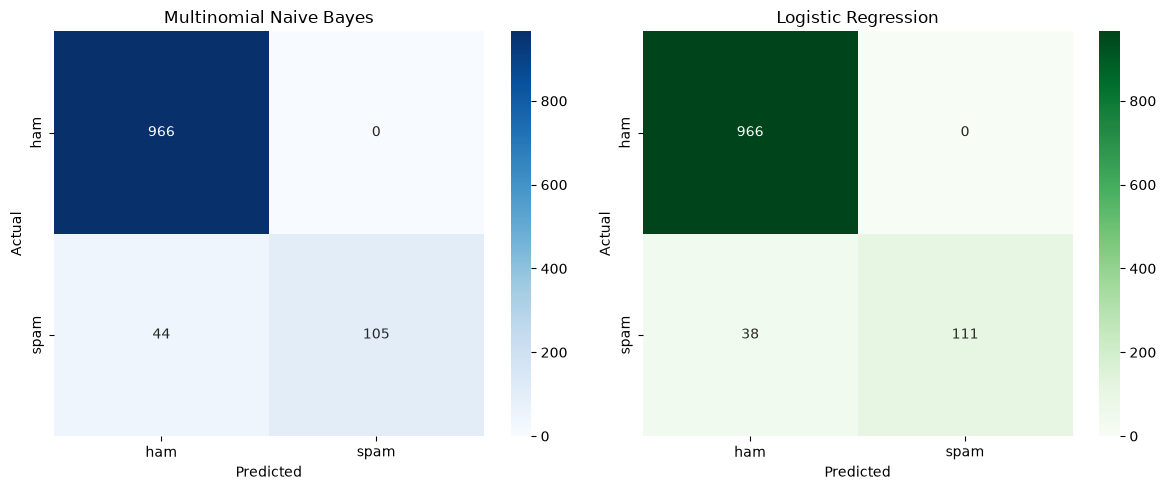

In [9]:
# Create confusion matrices for both models
nb_cm = confusion_matrix(y_test, nb_predictions, labels=["ham", "spam"])
lr_cm = confusion_matrix(y_test, lr_predictions, labels=["ham", "spam"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    nb_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"],
    ax=axes[0]
)
axes[0].set_title("Multinomial Naive Bayes")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    lr_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"],
    ax=axes[1]
)
axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 10. Classification Report

The classification report gives a detailed performance summary for each category. I will use it to compare how well both models identify spam and ham messages.

In [10]:
# Display classification reports
print("Multinomial Naive Bayes Classification Report")
print(classification_report(y_test, nb_predictions))

print("\nLogistic Regression Classification Report")
print(classification_report(y_test, lr_predictions))

Multinomial Naive Bayes Classification Report
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115


Logistic Regression Classification Report
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.74      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.92      1115
weighted avg       0.97      0.97      0.96      1115



### Observation

Both models performed well on the test dataset. Logistic Regression achieved 97% accuracy, while Multinomial Naive Bayes achieved 96% accuracy. Both models showed 100% precision for spam messages. However, Logistic Regression achieved better recall and F1-score, so it performed slightly better overall.

## 11. Importance of Recall in Spam Detection

Recall is important in spam detection because it tells us how many actual spam messages are correctly identified by the model.

If recall is low, some spam messages may be classified as genuine messages and reach the user's inbox. Therefore, a model with higher recall is useful because it can identify more spam messages.

In this project, Logistic Regression achieved higher spam recall than Multinomial Naive Bayes.

In [11]:
!pip install wordcloud

## 12. WordCloud Visualisation

In this section, I will create separate WordClouds for spam and ham messages. A WordCloud displays frequently used words in different sizes. Words that appear more often are shown in larger sizes.

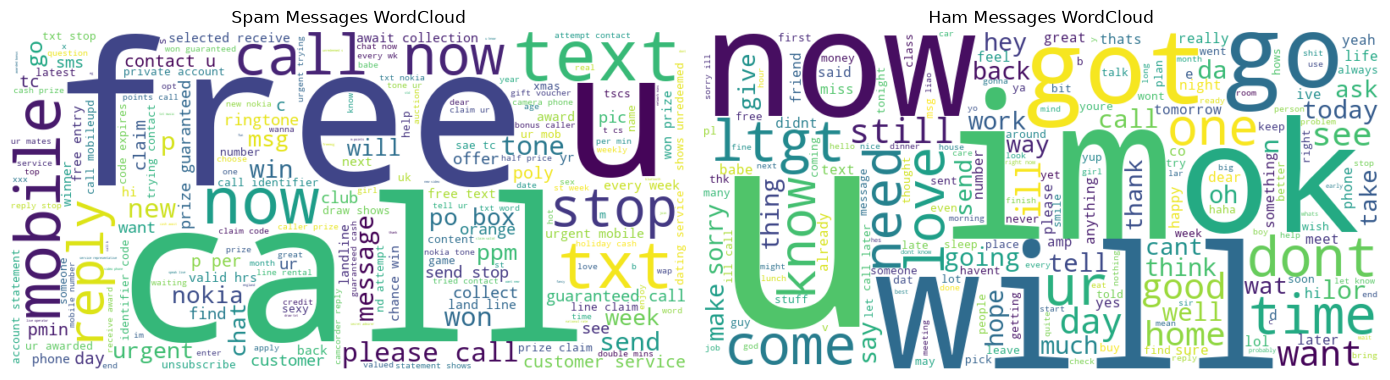

In [12]:
from wordcloud import WordCloud

# Combine all cleaned spam messages
spam_text = " ".join(df[df["Category"] == "spam"]["Clean_Message"])

# Combine all cleaned ham messages
ham_text = " ".join(df[df["Category"] == "ham"]["Clean_Message"])

# Create WordCloud for spam messages
spam_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(spam_text)

# Create WordCloud for ham messages
ham_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(ham_text)

# Display both WordClouds
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(spam_wordcloud, interpolation="bilinear")
plt.title("Spam Messages WordCloud")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ham_wordcloud, interpolation="bilinear")
plt.title("Ham Messages WordCloud")
plt.axis("off")

plt.tight_layout()
plt.show()

## 13. Conclusion

In this project, I developed a machine learning model to classify SMS messages as spam or ham. I used text preprocessing and TF-IDF to convert messages into numerical features.

I trained two models: Multinomial Naive Bayes and Logistic Regression. Both models performed well, but Logistic Regression achieved better results with 97% accuracy and a spam F1-score of 0.85.

Through this project, I learned how text preprocessing, feature extraction and machine learning can be used for spam message detection.